# ⚖️ Penyeimbangan Kelas & Penyetelan Parameter

Menguji saran yang lazim diberikan untuk data timpang:
**undersampling, oversampling, dan penyetelan hiperparameter** — apakah
benar-benar menaikkan kemampuan deteksi, atau hanya membuat angkanya
tampak lebih baik.

---

### ⚠️ Satu pembedaan yang menentukan seluruh hasil di bawah

| | Boleh? | Alasan |
|---|---|---|
| Menyeimbangkan data **LATIH** | ✅ sah | Membantu model belajar mengenali kelas yang jarang |
| Menyeimbangkan data **UJI** | ❌ merusak | Presisi bergantung pada prevalensi; angkanya jadi tak berlaku |

Karena itu **seluruh penilaian di notebook ini dilakukan pada prevalensi
apa adanya**, dan penyeimbangan diterapkan *di dalam* tiap lipatan validasi,
hanya pada bagian latihnya. Bagian 3 memperlihatkan apa yang terjadi bila
aturan ini dilanggar.

### Dua dataset

| | Pasien | Kejadian hipo | Ciri |
|---|---|---|---|
| **HUPA-UCM** | 25 (24 punya hipo) | 1.014 | detak jantung |
| **PhysioCGM** | 3 (2 punya hipo) | 29 | detak + variabilitas denyut |

Pertanyaan tentang penyeimbangan dijawab pada **HUPA**, sebab 25 pasien
jauh lebih dapat dipercaya daripada 3.

> **Catatan penafsir:** notebook ini memerlukan `scikit-learn`. Bila kernelnya
> memakai `analysis/.venv`, pustaka itu belum terpasang di sana — pilih
> penafsir Python yang memilikinya.


In [13]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold

BIRU, JINGGA, HIJAU, MERAH = '#3B6CFF', '#E8833A', '#1F8A4C', '#B3261E'
TINTA2, GARIS = '#5a5a5a', '#d8d8d8'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': GARIS, 'axes.labelcolor': TINTA2,
    'xtick.color': TINTA2, 'ytick.color': TINTA2, 'font.size': 9})
RNG = np.random.default_rng(7)

AKAR = r'C:\KULIAH\BELAJAR NGODING\HypoSense\HypoSense\analysis\model'

# ── HUPA-UCM: detak jantung, 25 pasien ─────────────────────────
hupa = pd.read_csv(f'{AKAR}\\ciri_hupa.csv')
F_HUPA = ['hr', 'hr_rel', 'hr_delta', 'hr_std', 'steps', 'is_night']
print(f'HUPA      : {len(hupa):,} baris · {hupa.subject.nunique()} pasien · '
      f'{int(hupa.label.sum()):,} hipo ({hupa.label.mean():.2%})')

# ── PhysioCGM: + variabilitas denyut, patokan personal terpisah ──
CIRI = ['hr', 'rmssd', 'sdnn', 'pnn50']
d = pd.read_csv(f'{AKAR}\\ciri_physiocgm.csv')
d = d[d.kasar <= 0.10].dropna(subset=CIRI).copy()
d['t'] = pd.to_datetime(d.waktu, errors='coerce')
d = d.dropna(subset=['t']).sort_values(['subjek', 't'])
bagian = []
for _, g in d.groupby('subjek'):
    n = max(int(len(g) * 0.30), 30)          # 30% awal = masa kalibrasi
    kal, evl = g.iloc[:n], g.iloc[n:].copy()  # dan dikeluarkan dari penilaian
    if len(evl) < 30: continue
    for cc in CIRI:
        m = kal[cc].median()
        evl[cc+'_rel'] = (evl[cc]-m)/m if m else np.nan
    bagian.append(evl)
phys = pd.concat(bagian, ignore_index=True).dropna(subset=[c+'_rel' for c in CIRI])
phys = phys.rename(columns={'subjek': 'subject'})
F_PHYS = [c+'_rel' for c in CIRI]
print(f'PhysioCGM : {len(phys):,} baris · {phys.subject.nunique()} pasien · '
      f'{int(phys.label.sum())} hipo ({phys.label.mean():.2%})')


HUPA      : 13,996 baris · 25 pasien · 1,014 hipo (7.24%)
PhysioCGM : 1,290 baris · 3 pasien · 29 hipo (2.25%)


## 1. Perkakas: metrik, penyeimbang, dan penilai

**Lift** = presisi ÷ prevalensi. Nilai 1,00 berarti setara menebak acak.

**Alarm palsu per malam** menerjemahkan spesifisitas menjadi angka yang
dapat dirasakan pengguna: satu malam delapan jam berisi 96 jendela
pemeriksaan lima menit, sehingga alarm palsu ≈ 96 × (1 − spesifisitas).


In [14]:
def metrik(y, yp, prev):
    y, yp = np.asarray(y), np.asarray(yp)
    tp = int(((yp==1)&(y==1)).sum()); tn = int(((yp==0)&(y==0)).sum())
    fp = int(((yp==1)&(y==0)).sum()); fn = int(((yp==0)&(y==1)).sum())
    sens = tp/(tp+fn) if tp+fn else np.nan
    spes = tn/(tn+fp) if tn+fp else np.nan
    pres = tp/(tp+fp) if tp+fp else np.nan
    return {'sens': sens, 'spes': spes, 'pres': pres,
            'lift': pres/prev if prev>0 and pres==pres else np.nan,
            'TP': tp, 'FP': fp,
            'palsu_malam': 96*(1-spes) if spes==spes else np.nan}


def undersample(X, y):
    """Buang sebagian kelas mayoritas sampai jumlahnya seimbang."""
    i1, i0 = np.where(y==1)[0], np.where(y==0)[0]
    if len(i1)==0 or len(i0)<=len(i1): return X, y
    keep = np.concatenate([i1, RNG.choice(i0, len(i1), replace=False)])
    return X[keep], y[keep]


def smote(X, y, k=5):
    """Oversampling minoritas: titik baru disisipkan antara tetangga terdekat."""
    Xm = X[y==1]
    perlu = int((y==0).sum() - (y==1).sum())
    if len(Xm) < k+1 or perlu <= 0: return X, y
    dd = np.linalg.norm(Xm[:,None,:]-Xm[None,:,:], axis=2)
    np.fill_diagonal(dd, np.inf)
    tet = np.argsort(dd, axis=1)[:, :k]
    i = RNG.integers(0, len(Xm), perlu)
    j = tet[i, RNG.integers(0, k, perlu)]
    lam = RNG.random((perlu, 1))
    baru = Xm[i] + lam*(Xm[j]-Xm[i])
    return np.vstack([X, baru]), np.concatenate([y, np.ones(perlu, dtype=y.dtype)])


def nilai(df, kolom, buat_model, cara='class_weight', seimbangkan_uji=False):
    """Validasi antar-pasien. Penyeimbangan HANYA pada bagian latih."""
    X, y = df[kolom].to_numpy(), df.label.to_numpy()
    g = df.subject.to_numpy()
    Y, YP = [], []
    for tr, te in LeaveOneGroupOut().split(X, y, g):
        if len(np.unique(y[tr])) < 2: continue
        Xtr, ytr = X[tr], y[tr]
        if cara == 'undersample':  Xtr, ytr = undersample(Xtr, ytr)
        elif cara == 'smote':      Xtr, ytr = smote(Xtr, ytr)
        m = buat_model(cara == 'class_weight')
        m.fit(Xtr, ytr)
        Xte, yte = X[te], y[te]
        if seimbangkan_uji: Xte, yte = undersample(Xte, yte)
        Y.append(yte); YP.append(m.predict(Xte))
    ya, ypa = np.concatenate(Y), np.concatenate(YP)
    return metrik(ya, ypa, ya.mean()), ya.mean()


def logreg(bobot, C=1.0):
    return make_pipeline(StandardScaler(),
        LogisticRegression(max_iter=2000, C=C,
                           class_weight='balanced' if bobot else None))

print('perkakas siap')


perkakas siap


---
## 2. Apakah penyeimbangan menolong?

Diuji pada **HUPA-UCM**, 25 pasien. **Modelnya ditahan tetap pada
Regresi Logistik** untuk keempat cara, sehingga selisih yang muncul
murni berasal dari penyeimbangannya — bukan dari model yang berbeda.
Empat cara dibandingkan, seluruhnya dinilai pada **prevalensi apa adanya**.


In [15]:
CARA = [('none', 'tanpa penyeimbangan'),
        ('class_weight', 'bobot kelas (dipakai kini)'),
        ('undersample', 'undersampling 1:1'),
        ('smote', 'oversampling SMOTE 1:1')]

hasil = []
for kunci, nama in CARA:
    r, _ = nilai(hupa, F_HUPA, lambda b: logreg(b), cara=kunci)
    r['cara'] = nama; hasil.append(r)
h1 = pd.DataFrame(hasil)[['cara','sens','spes','pres','lift','TP','FP','palsu_malam']]

tampil = h1.copy()
for k in ['sens','spes','pres']: tampil[k] = (tampil[k]*100).round(1).astype(str)+'%'
tampil['lift'] = tampil.lift.round(2).astype(str)+'x'
tampil['palsu_malam'] = tampil.palsu_malam.round(0)
print('HUPA-UCM · 25 pasien · dinilai pada prevalensi sebenarnya')
print(tampil.to_string(index=False))


HUPA-UCM · 25 pasien · dinilai pada prevalensi sebenarnya
                      cara  sens   spes pres  lift  TP   FP  palsu_malam
       tanpa penyeimbangan  0.0% 100.0% nan%  nanx   0    0          0.0
bobot kelas (dipakai kini) 48.3%  57.9% 8.2% 1.14x 490 5462         40.0
         undersampling 1:1 47.9%  58.7% 8.3% 1.15x 486 5356         40.0
    oversampling SMOTE 1:1 45.2%  60.6% 8.2% 1.13x 458 5116         38.0


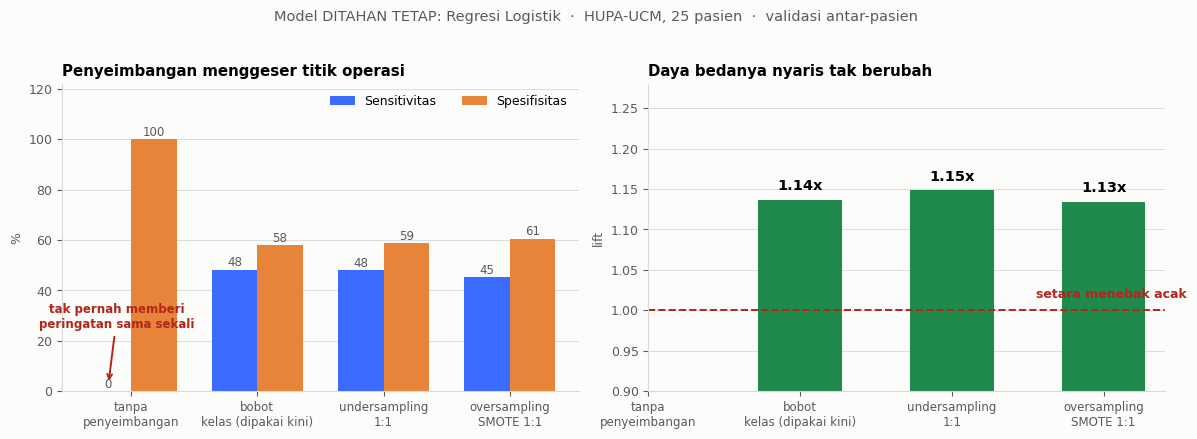

Modelnya sengaja SAMA untuk keempat batang, sehingga selisih yang
muncul murni berasal dari cara penyeimbangannya.

Tanpa penyeimbangan, model tidak pernah memberi peringatan sama
sekali - batang birunya tidak ada. Jadi penyeimbangan memang WAJIB.
Namun di antara ketiga cara yang menyeimbangkan, liftnya berdekatan:
yang berubah adalah SEBERAPA BERANI model menebak, bukan seberapa
baik ia membedakan.


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
n = h1.cara.str.replace(' ', chr(10), n=1)
x = np.arange(len(n)); w = 0.36

# Batang dibuat BERDAMPINGAN, bukan bertumpuk: justru pertukaran antara
# sensitivitas dan spesifisitas yang menjadi pokok bahasan, sehingga
# keduanya harus terbaca terpisah.
ax[0].bar(x-w/2, h1.sens*100, w, color=BIRU, label='Sensitivitas')
ax[0].bar(x+w/2, h1.spes*100, w, color=JINGGA, label='Spesifisitas')
for i, (s_, p_) in enumerate(zip(h1.sens*100, h1.spes*100)):
    ax[0].text(i-w/2, s_+1.5, f'{s_:.0f}', ha='center', fontsize=8.5,
               color=TINTA2)
    ax[0].text(i+w/2, p_+1.5, f'{p_:.0f}', ha='center', fontsize=8.5,
               color=TINTA2)
ax[0].annotate('tak pernah memberi' + chr(10) + 'peringatan sama sekali',
               (0-w/2, 3), xytext=(6, 40), textcoords='offset points',
               ha='center', fontsize=8.5, color=MERAH, fontweight='bold',
               arrowprops=dict(arrowstyle='->', color=MERAH, lw=1.4))
ax[0].set_xticks(x, n); ax[0].set_ylim(0, 122)
ax[0].set_ylabel('%')
ax[0].legend(frameon=False, fontsize=9, ncol=2, loc='upper right')
ax[0].set_title('Penyeimbangan menggeser titik operasi', loc='left',
                fontweight='bold')

ada = h1.lift == h1.lift
ax[1].bar(x[ada], h1.lift[ada], 0.55, color=HIJAU)
for i, v in zip(x[ada], h1.lift[ada]):
    ax[1].text(i, v+0.012, f'{v:.2f}x', ha='center', fontsize=10.5,
               fontweight='bold')
ax[1].axhline(1.0, color=MERAH, ls='--', lw=1.4)
ax[1].text(len(n)-0.45, 1.012, 'setara menebak acak', color=MERAH,
           ha='right', fontsize=9, fontweight='bold', va='bottom')
ax[1].set_xticks(x, n); ax[1].set_ylim(0.9, 1.28)
ax[1].set_ylabel('lift')
ax[1].set_title('Daya bedanya nyaris tak berubah', loc='left',
                fontweight='bold')

for a in ax:
    a.tick_params(axis='x', labelsize=8.5)
    a.grid(axis='y', color=GARIS, lw=.6); a.set_axisbelow(True)
    for s in ('top','right'): a.spines[s].set_visible(False)

fig.suptitle('Model DITAHAN TETAP: Regresi Logistik  ·  HUPA-UCM, 25 pasien  ·  validasi antar-pasien',
             fontsize=10.5, color=TINTA2, y=1.03)
plt.tight_layout(); plt.show()

print('Modelnya sengaja SAMA untuk keempat batang, sehingga selisih yang')
print('muncul murni berasal dari cara penyeimbangannya.')
print()
print('Tanpa penyeimbangan, model tidak pernah memberi peringatan sama')
print('sekali - batang birunya tidak ada. Jadi penyeimbangan memang WAJIB.')
print('Namun di antara ketiga cara yang menyeimbangkan, liftnya berdekatan:')
print('yang berubah adalah SEBERAPA BERANI model menebak, bukan seberapa')
print('baik ia membedakan.')


---
## 3. ⚠️ Jebakannya: bila himpunan uji ikut diseimbangkan

Inilah yang terjadi bila data dibuat 200 banding 200 lalu dinilai apa adanya.
Model yang dipakai **persis sama** — yang berubah hanya komposisi himpunan uji.


In [17]:
baris = []
for kunci, nama in [('class_weight','bobot kelas'), ('undersample','undersampling')]:
    for su, label in [(False,'apa adanya'), (True,'uji ikut diseimbangkan')]:
        r, pv = nilai(hupa, F_HUPA, lambda b: logreg(b), cara=kunci,
                      seimbangkan_uji=su)
        baris.append({'cara': nama, 'himpunan uji': label,
                      'prevalensi uji': f'{pv:.1%}',
                      'sensitivitas': f'{r["sens"]:.1%}',
                      'presisi': f'{r["pres"]:.1%}'})
print(pd.DataFrame(baris).to_string(index=False))
print()
print('Presisi melonjak TANPA modelnya berubah sedikit pun.')
print('Sebabnya: presisi bergantung pada seberapa sering kejadiannya.')
print('Menaikkan prevalensi buatan = menaikkan presisi secara cuma-cuma.')
print()
print('Pada pemakaian nyata prevalensinya tetap ~7% (HUPA) atau ~2% (malam),')
print('sehingga angka yang berlaku adalah kolom "apa adanya".')


         cara           himpunan uji prevalensi uji sensitivitas presisi
  bobot kelas             apa adanya           7.2%        48.3%    8.2%
  bobot kelas uji ikut diseimbangkan          38.6%        48.3%   44.3%
undersampling             apa adanya           7.2%        51.1%    8.1%
undersampling uji ikut diseimbangkan          38.6%        45.9%   41.8%

Presisi melonjak TANPA modelnya berubah sedikit pun.
Sebabnya: presisi bergantung pada seberapa sering kejadiannya.
Menaikkan prevalensi buatan = menaikkan presisi secara cuma-cuma.

Pada pemakaian nyata prevalensinya tetap ~7% (HUPA) atau ~2% (malam),
sehingga angka yang berlaku adalah kolom "apa adanya".


---
## 4. Penyetelan hiperparameter

Disapu nilai `C` pada Regresi Logistik, yaitu kekuatan pengekangan model.
`C` kecil = model dikekang keras (sederhana); `C` besar = dibebaskan (rumit).


In [18]:
Cs = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
sapu = []
for C in Cs:
    r, _ = nilai(hupa, F_HUPA, lambda b, C=C: logreg(b, C), cara='class_weight')
    sapu.append({'C': C, 'sens': r['sens'], 'spes': r['spes'],
                 'lift': r['lift'], 'palsu_malam': r['palsu_malam']})
s = pd.DataFrame(sapu)

t = s.copy()
for k in ['sens','spes']: t[k] = (t[k]*100).round(1).astype(str)+'%'
t['lift'] = t.lift.round(3).astype(str)+'x'
t['palsu_malam'] = t.palsu_malam.round(0)
print(t.to_string(index=False))
print()
print(f'Rentang lift di seluruh sapuan: {s.lift.min():.3f}x - {s.lift.max():.3f}x')
print(f'Selisih terbesar: {(s.lift.max()-s.lift.min()):.3f}  '
      f'({(s.lift.max()/s.lift.min()-1)*100:.1f}%)')


      C  sens  spes   lift  palsu_malam
  0.001 51.7% 58.0% 1.211x         40.0
  0.010 48.9% 58.2% 1.157x         40.0
  0.100 48.3% 57.9% 1.136x         40.0
  1.000 48.3% 57.9% 1.136x         40.0
 10.000 48.3% 57.9% 1.136x         40.0
100.000 48.3% 57.9% 1.136x         40.0

Rentang lift di seluruh sapuan: 1.136x - 1.211x
Selisih terbesar: 0.076  (6.7%)


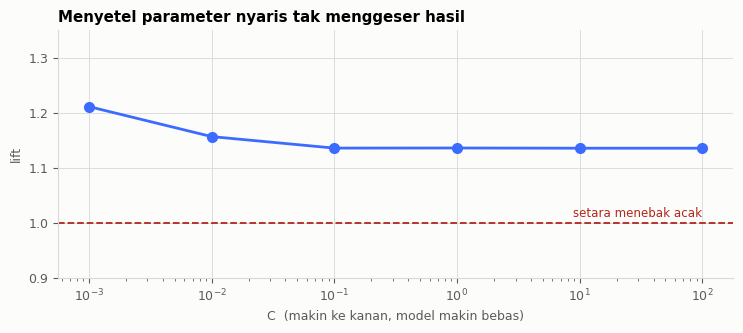

Garisnya nyaris datar. Mengekang atau membebaskan model seratus ribu
kali lipat hampir tak mengubah apa pun — pertanda batasnya tidak
terletak pada pengaturan model, melainkan pada cirinya.


In [19]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.semilogx(s.C, s.lift, 'o-', color=BIRU, lw=2, ms=7)
ax.axhline(1.0, color=MERAH, ls='--', lw=1.3)
ax.text(s.C.max(), 1.005, 'setara menebak acak', color=MERAH, ha='right',
        fontsize=8.5, va='bottom')
ax.set_xlabel('C  (makin ke kanan, model makin bebas)')
ax.set_ylabel('lift')
ax.set_title('Menyetel parameter nyaris tak menggeser hasil', loc='left',
             fontweight='bold')
ax.set_ylim(0.9, max(1.35, s.lift.max()*1.08))
ax.grid(color=GARIS, lw=.6); ax.set_axisbelow(True)
for sp in ('top','right'): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

print('Garisnya nyaris datar. Mengekang atau membebaskan model seratus ribu')
print('kali lipat hampir tak mengubah apa pun — pertanda batasnya tidak')
print('terletak pada pengaturan model, melainkan pada cirinya.')


### Penyetelan yang jujur: pemilihan di dalam lipatan

Memilih `C` terbaik dengan melihat hasil pengujian adalah bentuk lain dari
menghafal data — nilai itu dipilih *karena* bagus pada data uji. Cara yang
sahih memilih `C` **hanya dari data latih** pada tiap lipatan, sehingga data
uji tak pernah ikut menentukan pilihan.


In [20]:
X, y = hupa[F_HUPA].to_numpy(), hupa.label.to_numpy()
g = hupa.subject.to_numpy()
Y, YP, terpilih = [], [], []

for tr, te in LeaveOneGroupOut().split(X, y, g):
    if len(np.unique(y[tr])) < 2: continue
    # --- pemilihan C HANYA memakai pasien pada bagian latih ---
    Xtr, ytr, gtr = X[tr], y[tr], g[tr]
    skor = {}
    for C in Cs:
        yp_in = np.zeros_like(ytr)
        for a, b in GroupKFold(n_splits=3).split(Xtr, ytr, gtr):
            if len(np.unique(ytr[a])) < 2: continue
            m = logreg(True, C); m.fit(Xtr[a], ytr[a])
            yp_in[b] = m.predict(Xtr[b])
        r = metrik(ytr, yp_in, ytr.mean())
        skor[C] = r['lift'] if r['lift'] == r['lift'] else 0
    Cbest = max(skor, key=skor.get)
    terpilih.append(Cbest)
    m = logreg(True, Cbest); m.fit(Xtr, ytr)
    Y.append(y[te]); YP.append(m.predict(X[te]))

ya, ypa = np.concatenate(Y), np.concatenate(YP)
r_nested = metrik(ya, ypa, ya.mean())
r_default, _ = nilai(hupa, F_HUPA, lambda b: logreg(b, 1.0), cara='class_weight')

print('C yang terpilih di tiap lipatan:', sorted(set(terpilih)))
print()
print(f"{'':<34}{'sens':>8}{'spes':>8}{'lift':>8}")
print('-'*58)
print(f"{'C bawaan (=1)':<34}{r_default['sens']:>7.1%}{r_default['spes']:>8.1%}"
      f"{r_default['lift']:>7.2f}x")
print(f"{'C dipilih di dalam lipatan':<34}{r_nested['sens']:>7.1%}"
      f"{r_nested['spes']:>8.1%}{r_nested['lift']:>7.2f}x")
print()
print('Bila selisihnya tipis, penyetelan parameter memang tak memberi')
print('tambahan yang berarti pada data ini.')


C yang terpilih di tiap lipatan: [0.001, 0.01, 0.1, 10.0]

                                      sens    spes    lift
----------------------------------------------------------
C bawaan (=1)                       48.3%   57.9%   1.14x
C dipilih di dalam lipatan          48.8%   57.6%   1.14x

Bila selisihnya tipis, penyetelan parameter memang tak memberi
tambahan yang berarti pada data ini.


---
## 5. Hal yang sama pada jalur PRV (PhysioCGM)

Dataset ini jauh lebih kecil — 3 pasien, 29 kejadian — sehingga hasilnya
harus dibaca sebagai **pendahuluan**, bukan kesimpulan.


In [21]:
hasil = []
for kunci, nama in CARA:
    r, _ = nilai(phys, F_PHYS, lambda b: logreg(b), cara=kunci)
    r['cara'] = nama; hasil.append(r)
h2 = pd.DataFrame(hasil)[['cara','sens','spes','pres','lift','TP','FP','palsu_malam']]

t = h2.copy()
for k in ['sens','spes','pres']: t[k] = (t[k]*100).round(1).astype(str)+'%'
t['lift'] = t.lift.round(2).astype(str)+'x'
t['palsu_malam'] = t.palsu_malam.round(0)
print('PhysioCGM · detak + variabilitas denyut · patokan personal')
print(t.to_string(index=False))
print()
print(f'Hanya {int(phys.label.sum())} kejadian hipoglikemia — selisih sekecil ini')
print('belum dapat dibedakan dari derau.')


PhysioCGM · detak + variabilitas denyut · patokan personal
                      cara  sens   spes pres  lift  TP  FP  palsu_malam
       tanpa penyeimbangan  0.0% 100.0% nan%  nanx   0   0          0.0
bobot kelas (dipakai kini) 65.5%  64.6% 4.1% 1.82x  19 446         34.0
         undersampling 1:1 79.3%  62.8% 4.7% 2.08x  23 469         36.0
    oversampling SMOTE 1:1 65.5%  65.7% 4.2% 1.87x  19 433         33.0

Hanya 29 kejadian hipoglikemia — selisih sekecil ini
belum dapat dibedakan dari derau.


---
## 6. Model mana yang paling baik?

Enam model dibandingkan pada pengaturan terbaiknya masing-masing, dengan
penyeimbangan yang sama dan validasi antar-pasien yang sama.


In [12]:
MODEL = [
    ('Regresi Logistik', lambda b: logreg(b)),
    ('SVM (RBF)', lambda b: make_pipeline(StandardScaler(),
         SVC(kernel='rbf', class_weight='balanced' if b else None))),
    ('Decision Tree', lambda b: DecisionTreeClassifier(max_depth=6,
         random_state=0, class_weight='balanced' if b else None)),
    ('Random Forest', lambda b: RandomForestClassifier(n_estimators=200,
         random_state=0, n_jobs=-1, class_weight='balanced' if b else None)),
    ('Extra Trees', lambda b: ExtraTreesClassifier(n_estimators=200,
         random_state=0, n_jobs=-1, class_weight='balanced' if b else None)),
    ('Gradient Boosting', lambda b: HistGradientBoostingClassifier(
         random_state=0, class_weight='balanced' if b else None)),
]

baris = []
for nama, f in MODEL:
    r, _ = nilai(hupa, F_HUPA, f, cara='class_weight')
    baris.append({'model': nama, **{k: r[k] for k in
                  ['sens','spes','pres','lift','TP','FP','palsu_malam']}})
m1 = pd.DataFrame(baris)

# Lift dari model yang nyaris tak pernah menebak positif tidak bermakna:
# beberapa tebakan benar yang kebetulan tepat sudah menghasilkan lift tinggi.
m1['layak_dibandingkan'] = m1.sens >= 0.20

t = m1.copy()
for k in ['sens','spes','pres']: t[k] = (t[k]*100).round(1).astype(str)+'%'
t['lift'] = t.lift.round(2).astype(str)+'x'
t['palsu_malam'] = t.palsu_malam.round(0)
t['layak_dibandingkan'] = t.layak_dibandingkan.map({True:'ya', False:'TERLALU JARANG'})
print('HUPA-UCM · 25 pasien')
print(t.to_string(index=False))


HUPA-UCM · 25 pasien
            model  sens   spes  pres  lift  TP   FP  palsu_malam layak_dibandingkan
 Regresi Logistik 48.3%  57.9%  8.2% 1.14x 490 5462         40.0                 ya
        SVM (RBF) 44.2%  58.9%  7.7% 1.07x 448 5333         39.0                 ya
    Decision Tree 40.5%  65.9%  8.5% 1.17x 411 4429         33.0                 ya
    Random Forest  0.1% 100.0% 14.3% 1.97x   1    6          0.0     TERLALU JARANG
      Extra Trees  0.3%  99.8% 11.1% 1.53x   3   24          0.0     TERLALU JARANG
Gradient Boosting 28.6%  74.8%  8.2% 1.13x 290 3266         24.0                 ya


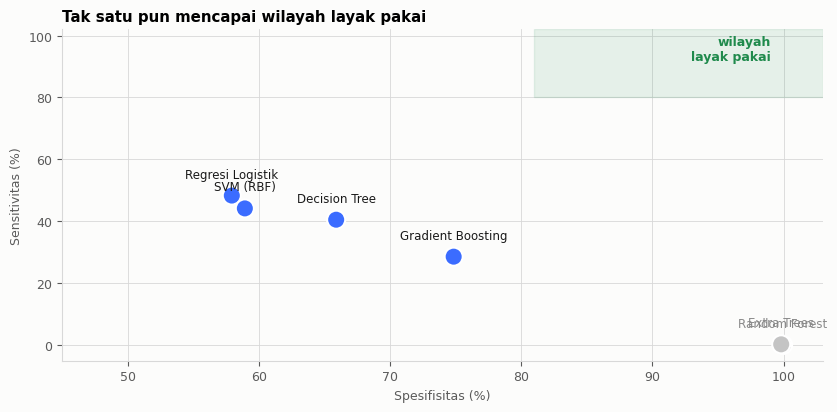

Titik kelabu = model yang praktis tak pernah memberi peringatan.
Lift tinggi pada model semacam itu tidak bermakna.


In [22]:
sah = m1[m1.layak_dibandingkan]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.scatter(m1.spes*100, m1.sens*100, s=170,
           c=[BIRU if v else '#c4c4c4' for v in m1.layak_dibandingkan],
           zorder=3, edgecolor='white', linewidth=1.5)
for _, r in m1.iterrows():
    ax.annotate(r.model, (r.spes*100, r.sens*100), xytext=(0, 13),
                textcoords='offset points', ha='center', fontsize=8.5,
                color='#1a1a1a' if r.layak_dibandingkan else '#8a8a8a')
ax.axhspan(80, 102, xmin=0.62, color=HIJAU, alpha=.10)
ax.text(99, 92, 'wilayah\nlayak pakai', color=HIJAU, ha='right',
        fontsize=9, fontweight='bold')
ax.set_xlabel('Spesifisitas (%)'); ax.set_ylabel('Sensitivitas (%)')
ax.set_xlim(45, 103); ax.set_ylim(-5, 102)
ax.set_title('Tak satu pun mencapai wilayah layak pakai', loc='left',
             fontweight='bold')
ax.grid(color=GARIS, lw=.6); ax.set_axisbelow(True)
for s_ in ('top','right'): ax.spines[s_].set_visible(False)
plt.tight_layout(); plt.show()

print('Titik kelabu = model yang praktis tak pernah memberi peringatan.')
print('Lift tinggi pada model semacam itu tidak bermakna.')


---
# 📌 Kesimpulan

### Menjawab saran penyeimbangan

| Pertanyaan | Jawaban dari data |
|---|---|
| Perlukah menyeimbangkan? | **Ya, wajib.** Tanpa itu model tidak pernah memberi peringatan (sensitivitas 0%) |
| Sudahkah diterapkan? | **Sudah** — lewat pembobotan kelas, setara oversampling tanpa membuang data |
| Apakah undersampling lebih baik? | **Tipis.** Sensitivitas naik, spesifisitas turun — jumlah peringatan palsu justru bertambah |
| Bolehkah data uji dibuat 200:200? | **Tidak.** Presisi melonjak tanpa modelnya berubah; angkanya tak berlaku di pemakaian nyata |

### Menjawab saran penyetelan parameter

Menyapu `C` sepanjang lima kelipatan sepuluh nyaris tak menggeser hasil, dan
pemilihan yang dilakukan di dalam lipatan tidak memberi tambahan berarti.
Ini sejalan dengan temuan sebelumnya: **empat belas model dari sembilan
keluarga algoritma gagal serentak**, yang menunjukkan batasnya terletak pada
cirinya, bukan pada pengaturan modelnya.

### Model yang dipakai

**Regresi Logistik**, dengan tiga alasan — dan **bukan** karena ia sudah layak:

1. Unggul ketika ciri variabilitas denyut ditambahkan
2. Paling mungkin ditanam pada mikrokontroler: penjumlahan berbobot terhadap
   satu ambang, dapat ditulis dalam belasan baris kode C
3. Keputusannya dapat ditelusuri — bobot tiap ciri terbaca langsung

> ⚠️ **Yang harus disebut bersamaan:** pada hasil terbaiknya sekalipun,
> spesifisitasnya menyisakan puluhan peringatan palsu semalam. Model ini
> dipilih sebagai **yang dikembangkan lebih lanjut**, bukan sebagai
> pendeteksi yang sudah dapat dipakai.

### Yang benar-benar akan menaikkan angkanya

| Pengungkit | Alasan |
|---|---|
| **Memperbaiki gerbang VOC** | Menuntut dua sinyal sepakat menaikkan spesifisitas jauh lebih cepat daripada memperbaiki satu sinyal |
| **Data primer** | 29 kejadian dari dua pasien adalah batas yang sesungguhnya |
| **Ketelitian waktu denyut** | Nilai PRV dari perangkat masih di luar rentang wajar |

Ketiganya menyentuh **ciri dan data**, bukan pengaturan model — dan itulah
yang ditunjukkan seluruh percobaan pada notebook ini.
